# 06 · Policy gradient: REINFORCE con baseline
**Entornos:** MiniDespacho (mediano) · **Tiempo de ejecución:** ≤ 7 min en CPU · **Criterio de la lección:** REINFORCE con baseline aprendido llega al menos a mitad de camino entre el aleatorio
y `GreedyDespacho` (s(0,5) ≥ 0,5, n = 1000), y el baseline reduce la varianza total del gradiente.

## 1. La idea en una frase
En vez de estimar valores y derivar la política, se **ajusta la política directamente**: se sube la probabilidad de las acciones que terminaron en buenos retornos y se baja la de las malas.

**En el sistema de Luca:** PPO es esto mismo con dos mejoras (ventaja GAE y actualización recortada); la cabeza de acción del Transformer es una política $\pi(a\mid s)$.
**En un problema de negocio:** la regla de despacho es una distribución sobre las asignaciones legales que se afina con el costo observado de cada día simulado.

## 2. La intuición y la fórmula
Con retorno-a-futuro $G_t=\sum_{k\ge t}\gamma^{k-t} r_k$, el gradiente de la política es

$$\nabla_\theta J = \mathbb{E}\Bigl[\sum_t \nabla_\theta \log \pi_\theta(a_t\mid s_t)\,\bigl(G_t - b(s_t)\bigr)\Bigr],$$

y se minimiza la pérdida $-\sum_t \log\pi(a_t\mid s_t)\,(G_t-b(s_t))$. El **baseline** $b(s_t)$ no cambia el valor esperado del gradiente pero **reduce su varianza**: con $b=0$ todas las
acciones de un episodio "buenos costos" suben aunque no aporten. Tres opciones: $b=0$; $b=$ media de los $G_t$ del lote; $b(s)=V_\phi(s)$ aprendido (el crítico).
La política enmascara las opciones ilegales, así que solo se muestrean acciones legales.

In [1]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, normalized_score_ci, passes_lower
from rlf.eval.arena import evaluate_policy
from rlf.envs.despacho import DespachoEnv
from rlf.agents.baselines import RandomPolicy, GreedyDespacho
from rlf.agents.reinforce import Reinforce
from rlf.agents.policy import ActorCriticPolicy
from rlf.nets.mlp import MLPActorCritic
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
make_env = lambda: DespachoEnv.from_size("mediano")
SPEC = make_env().spec

def new_agent(baseline="value", lr=1e-3, gamma=1.0, seed=TRAIN_SEED):
    torch.manual_seed(seed)
    net = MLPActorCritic(SPEC, hidden=(64, 64))
    # reward_scale: los retornos rondan −100; se dividen por U = 68 para que las ventajas sean O(1)
    return Reinforce(net, baseline=baseline, gamma=gamma, lr=lr, entropy_coef=0.01, reward_scale=1 / 68,
                     normalize_adv=True, seed=seed)

## 3. El núcleo: la pérdida de REINFORCE
La fórmula, escrita a mano. Una celda comprueba que da lo mismo que `Reinforce.loss` de `rlf` (sin normalizar ventajas, que es un añadido práctico).

In [2]:
def reinforce_loss_inline(logits, actions, returns, baseline_values):
    """−Σ_t log π(a_t|s_t) · (G_t − b(s_t)), promediado por paso. `baseline_values` ya viene sin gradiente."""
    logp = torch.log_softmax(logits, dim=-1).gather(1, actions[:, None]).squeeze(1)   # log π de la acción tomada
    return -(logp * (returns - baseline_values)).mean()

# verificación cruzada contra rlf (baseline de valor y de media)
for kind in ("value", "mean"):
    agent = new_agent(kind)
    agent.normalize_adv = False
    eps = agent.collect(VecEnv(make_env, 4, seed=3), 8)
    obs, a, g = agent._stack(eps)
    logits, value = agent.net(obs)
    b = value.detach() if kind == "value" else g.mean().detach().expand_as(g)
    mine = reinforce_loss_inline(logits, a, g, b)
    _, info = agent.loss(eps)
    assert abs(float(mine) - info["policy_loss"]) < 1e-6, (kind, float(mine), info["policy_loss"])
print("pérdida inline == rlf (baseline de valor y de media)")

pérdida inline == rlf (baseline de valor y de media)


/tmp/ipykernel_2195/1479308837.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  assert abs(float(mine) - info["policy_loss"]) < 1e-6, (kind, float(mine), info["policy_loss"])


## 4. Entrenar y graficar la curva de aprendizaje
800 actualizaciones de 64 episodios completos cada una (≈ 51 000 episodios). REINFORCE optimiza la política **estocástica**, así que la evaluamos muestreando de ella.
Cada 200 actualizaciones medimos el puntaje normalizado $s(0{,}5)$ con n = 1000 semillas de evaluación.

aleatorio -118.2   greedy -77.5   (mitad de camino: -97.8)


 200 actualizaciones: retorno  -94.86   s(0,5): media de d_i   2.96  IC95 [  0.58,   5.34]


 400 actualizaciones: retorno  -96.58   s(0,5): media de d_i   1.25  IC95 [ -1.06,   3.56]


 600 actualizaciones: retorno  -92.37   s(0,5): media de d_i   5.46  IC95 [  3.17,   7.74]


 800 actualizaciones: retorno  -91.21   s(0,5): media de d_i   6.61  IC95 [  4.33,   8.90]


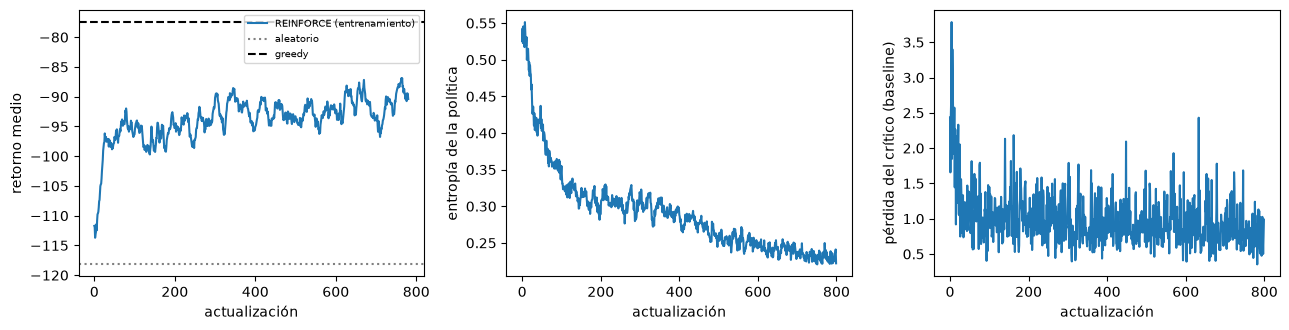

In [3]:
N = 1000
rand_ret = evaluate_policy(make_env, RandomPolicy(TRAIN_SEED), N)
greedy_ret = evaluate_policy(make_env, GreedyDespacho(), N)
print(f"aleatorio {rand_ret.mean():.1f}   greedy {greedy_ret.mean():.1f}   (mitad de camino: {(rand_ret.mean() + greedy_ret.mean()) / 2:.1f})")

N_UPDATES, EPS_PER_UPDATE = 800, 64
agent = new_agent("value")
vec = VecEnv(make_env, 16, seed=TRAIN_SEED)
checkpoints = {}
for start in range(0, N_UPDATES, 200):
    agent.train(vec, 200, EPS_PER_UPDATE)
    ret = evaluate_policy(make_env, ActorCriticPolicy(agent.net, greedy=False, seed=TRAIN_SEED), N)
    checkpoints[start + 200] = normalized_score_ci(ret, rand_ret, greedy_ret, alpha=0.5)
    print(f"{start + 200:4d} actualizaciones: retorno {ret.mean():7.2f}   s(0,5): media de d_i {checkpoints[start + 200].mean:6.2f}  IC95 [{checkpoints[start + 200].lo:6.2f}, {checkpoints[start + 200].hi:6.2f}]")

hist = agent.history
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
w = 20
ax[0].plot(np.convolve([h["mean_return"] for h in hist], np.ones(w) / w, mode="valid"), label="REINFORCE (entrenamiento)")
ax[0].axhline(rand_ret.mean(), color="gray", ls=":", label="aleatorio"); ax[0].axhline(greedy_ret.mean(), color="k", ls="--", label="greedy")
ax[0].set_xlabel("actualización"); ax[0].set_ylabel("retorno medio"); ax[0].legend(fontsize=7)
ax[1].plot([h["entropy"] for h in hist]); ax[1].set_xlabel("actualización"); ax[1].set_ylabel("entropía de la política")
ax[2].plot([h["value_loss"] for h in hist]); ax[2].set_xlabel("actualización"); ax[2].set_ylabel("pérdida del crítico (baseline)")
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"

### Experimento 1 · Sin baseline vs baseline de media vs baseline aprendido
**Predice:** con la política final fija y 1000 episodios, ¿cuál baseline da la menor varianza total del gradiente por episodio? (suma sobre parámetros de la varianza de cada componente).

In [4]:
eps_1000 = agent.collect(VecEnv(make_env, 16, seed=TRAIN_SEED + 7), N)[:N]
assert len(eps_1000) == N
mean_g = float(np.concatenate([e.returns for e in eps_1000]).mean())
def total_gradient_variance(baseline_value):
    grads = torch.stack([agent.episode_gradient(e, baseline_value) for e in eps_1000])
    return float(grads.var(dim=0, unbiased=True).sum())
var_none = total_gradient_variance(0.0)
var_mean = total_gradient_variance(mean_g)
var_value = total_gradient_variance(None)                      # None => baseline aprendido V(s_t)
print(f"varianza total del gradiente: b=0 {var_none:.1f}   b=media {var_mean:.1f}   b=V(s) {var_value:.1f}")
print(f"cocientes respecto de b=0: media {var_mean / var_none:.3f}   valor {var_value / var_none:.3f}")
assert var_value < var_none and var_mean < var_none

varianza total del gradiente: b=0 225.2   b=media 116.4   b=V(s) 89.8
cocientes respecto de b=0: media 0.517   valor 0.399


<details><summary>Respuesta esperada</summary>

Los dos baselines reducen la varianza respecto de $b=0$: la media a ≈ 52 % y el baseline aprendido a ≈ 40 % (varianza total ≈ 225 → 116 → 90). El baseline no cambia el gradiente esperado, solo lo hace más estable: con
$b=0$ los retornos son todos negativos y cada episodio empuja hacia "hacer menos de lo que hizo", con mucho ruido.
</details>

### Experimento 2 · Tasa de aprendizaje ×10
**Predice:** ¿aprende más rápido con `lr = 1e-2` o se vuelve inestable? (200 actualizaciones, se compara con el punto de 200 actualizaciones de la curva).

In [5]:
fast = new_agent("value", lr=1e-2)
fast.train(VecEnv(make_env, 16, seed=TRAIN_SEED), 200, EPS_PER_UPDATE)
ret_fast = evaluate_policy(make_env, ActorCriticPolicy(fast.net, greedy=False, seed=TRAIN_SEED), N)
s_fast = normalized_score_ci(ret_fast, rand_ret, greedy_ret, 0.5)
print(f"lr 1e-2: retorno {ret_fast.mean():.2f}, s(0,5) {s_fast.mean:.2f} [{s_fast.lo:.2f}, {s_fast.hi:.2f}];  lr 1e-3 a las 200: media d_i {checkpoints[200].mean:.2f}")
assert s_fast.mean > checkpoints[200].mean and s_fast.lo > 0

lr 1e-2: retorno -91.13, s(0,5) 6.69 [4.37, 9.01];  lr 1e-3 a las 200: media d_i 2.96


<details><summary>Respuesta esperada</summary>

Con esta configuración (Adam, ventajas normalizadas y recorte de gradiente) **no se vuelve inestable**: con `lr = 1e-2` a las 200 actualizaciones ya está al nivel que `lr = 1e-3` logra a las 800
(retorno ≈ −91 frente a ≈ −95 con `lr = 1e-3` a las 200). Sin esas protecciones, una tasa 10 veces mayor suele hacer colapsar la política; aquí las protecciones absorben el riesgo.
</details>

### Experimento 3 · Entropía de la política durante el entrenamiento
**Predice:** ¿sube, baja o se queda igual? ¿Llega a colapsar a una política determinista?

In [6]:
ent = np.array([h["entropy"] for h in hist])
print(f"entropía: primeras 50 actualizaciones {ent[:50].mean():.3f}, últimas 50 {ent[-50:].mean():.3f}")
assert ent[:50].mean() > ent[-50:].mean() > 0.05

entropía: primeras 50 actualizaciones 0.464, últimas 50 0.231


<details><summary>Respuesta esperada</summary>

**Baja** (de ≈ 0,5 a ≈ 0,2): la política pasa de explorar a concentrarse en las acciones que funcionan, pero sin colapsar del todo (queda > 0,05) gracias al bono de entropía (0,01).
Si la entropía cayera a ≈ 0 demasiado pronto, la política dejaría de explorar y el aprendizaje se estancaría.
</details>

### Experimento 4 · ¿Ayuda γ < 1?
**Predice:** con γ = 0,9 (200 actualizaciones), ¿aprende mejor o peor que con γ = 1? Se evalúa siempre el retorno **sin descontar**.

In [7]:
disc = new_agent("value", gamma=0.9)
disc.train(VecEnv(make_env, 16, seed=TRAIN_SEED), 200, EPS_PER_UPDATE)
ret_disc = evaluate_policy(make_env, ActorCriticPolicy(disc.net, greedy=False, seed=TRAIN_SEED), N)
d_disc = paired_diff_ci(ret_disc, rand_ret)
s_disc = normalized_score_ci(ret_disc, rand_ret, greedy_ret, 0.5)
print(f"γ=0,9: retorno {ret_disc.mean():.2f}, mejora sobre el aleatorio {d_disc.mean:.1f} [{d_disc.lo:.1f}, {d_disc.hi:.1f}]; media d_i {s_disc.mean:.2f} (γ=1 a las 200: {checkpoints[200].mean:.2f})")
assert d_disc.lo > 0

γ=0,9: retorno -90.79, mejora sobre el aleatorio 27.4 [24.2, 30.6]; media d_i 7.04 (γ=1 a las 200: 2.96)


<details><summary>Respuesta esperada</summary>

Aprende (mejora al aleatorio con LB > 0) y en esta corrida rinde **algo mejor** que γ = 1 a igual número de actualizaciones (retorno ≈ −90,8 frente a ≈ −94,9; media de $d_i$ ≈ 7,0 frente a ≈ 3,0).
Descontar reduce la varianza de $G_t$ (mira menos lejos) a costa de un sesgo respecto del objetivo real (costo total sin descontar). Con una sola semilla de entrenamiento
esa diferencia no es concluyente: haría falta repetir con varias semillas antes de afirmar que γ < 1 ayuda.
</details>

## 6. Criterio de la lección
n = 1000 semillas de evaluación; política final (800 actualizaciones) muestreada.

In [8]:
score = checkpoints[N_UPDATES]
ok_a = passes_lower(score, 0.0)                              # (a) s(0,5) ≥ 0,5  ⇔  LB de mean(d_i) ≥ 0
ratio = var_value / var_none
ok_b = ratio < 1.0                                           # (b) chequeo determinista: cociente < 1
print(f"{'afirmación':78s} resultado")
print(f"{'(a) s(0,5): media de d_i %.2f, IC95 [%.2f, %.2f], LB ≥ 0' % (score.mean, score.lo, score.hi):78s} {ok_a}")
print(f"{'(b) varianza del gradiente con baseline aprendido / con b=0 = %.3f < 1' % ratio:78s} {ok_b}")
assert ok_a and ok_b

afirmación                                                                     resultado
(a) s(0,5): media de d_i 6.61, IC95 [4.33, 8.90], LB ≥ 0                       True
(b) varianza del gradiente con baseline aprendido / con b=0 = 0.399 < 1        True


## 7. Resumen y puente a la lección siguiente
- Policy gradient ajusta la política directamente; el baseline no sesga el gradiente y baja su varianza (aquí a ≈ 40 % con el crítico).
- Con la misma pérdida, REINFORCE mejora al aleatorio y supera la mitad de camino hacia greedy, pero es lento y ruidoso (≈ 51 000 episodios para quedar aún por debajo de greedy).
- **Lección 7:** actor-crítico con GAE y la actualización recortada de PPO: más eficiente en datos y más estable.